# Tech Challenge 1



# 1. Entendimento de negócio

<div style="text-align: justify;">
O **Net Promoter Score (NPS)** é um indicador utilizado para avaliar a satisfação e a lealdade dos clientes a partir da probabilidade de recomendarem uma empresa, produto ou serviço. Além de acompanhar a percepção geral dos consumidores, o NPS pode ser utilizado como ponto de partida para identificar problemas ao longo da jornada do cliente.

</div>

<br>

<div style="text-align: justify;">

**Classificação do NPS**  
A avaliação do NPS divide os clientes em três grupos de acordo com a nota atribuída:  
**1:** Detratores (0 a 6): clientes insatisfeitos, com maior possibilidade de compartilhar experiências negativas e menor propensão à recomendação.  
**2:** Neutros/Passivos (7 e 8): clientes satisfeitos, porém sem forte vínculo ou propensão à recomendação.  
**3:** Promotores (9 e 10): clientes altamente satisfeitos e mais propensos a recomendar a empresa.  

</div>

<br>

O indicador é calculado pela diferença entre o percentual de promotores e o percentual de detratores:  

<div align="center">
**NPS = % Promotores − % Detratores**
</div>

<br>

<div style="text-align: justify;">

Neste projeto, o objetivo é ir além do valor do indicador e entender quais fatores da experiência estão relacionados à satisfação dos clientes e, principalmente, à geração de detratores. Para isso, serão analisadas diferentes características da jornada de compra, buscando identificar padrões, pontos críticos e possíveis causas de insatisfação.
Problema de negócio

</div>

<br>

<div style="text-align: justify;">

**O principal problema a ser respondido é:**

**Quais fatores da jornada do cliente estão mais associados à satisfação e à classificação como detrator?**

A partir dessa pergunta, a análise buscará **identificar** os principais pontos de atrito na experiência e possíveis **pontos de ruptura**, ou seja, situações em que determinada variável passa a apresentar um **diferença relevante na satisfação do cliente**.

</div>

## Importância para o negócio


<div style="text-align: justify;">

Para um e-commerce, compreender esses fatores é especialmente importante, pois a experiência do cliente envolve diferentes etapas, como preço, compra, entrega, qualidade do produto, atendimento e resolução de problemas.
Identificar quais dessas etapas estão mais relacionadas à insatisfação permite transformar o NPS de um simples indicador de acompanhamento em uma ferramenta de diagnóstico e tomada de decisão.

<br>

Os resultados podem apoiar áreas como Logística, Atendimento, Customer Experience, Pricing, Produto e Marketing/CRM, ajudando na priorização de iniciativas voltadas à melhoria da experiência, redução de detratores e aumento da satisfação e fidelização dos clientes.

</div>

# Objetivos da análise
Com base no problema de negócio apresentado, a análise exploratória será conduzida buscando responder principalmente:
<br>
- Quais fatores parecem mais críticos para a satisfação dos clientes?
- Quais características estão mais associadas à geração de detratores?
- Existe algum ponto de ruptura na experiência do cliente?

# EDA - Análise exploratória de dados

### Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

arquivo = Path('desafio_nps_fase_1.csv')
if not arquivo.exists():
    arquivo = Path(r'C:/pos-graduacao/POSTECH_AI_SCIENTIST/Fase 1/tech_challenge/desafio_nps_fase_1.csv')

df = pd.read_csv(arquivo)

In [3]:
df

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2496,51,Sul,96,52496,615.81,6,11.41,2,14,3,28.96,2,1,2,3.7,0,3,4.3
2496,2497,37,Sul,89,52497,73.03,1,36.44,3,12,2,27.42,2,2,7,3.7,0,4,2.5
2497,2498,19,Sudeste,98,52498,522.78,1,4.84,9,2,2,38.94,1,1,1,7.4,0,3,6.2
2498,2499,41,Sul,51,52499,55.87,2,2.11,2,14,5,29.10,3,3,0,2.3,0,5,1.7


### Tamanho da base de dados

In [4]:
df.shape

(2500, 19)

### Verificando o tipo dos dados e dados nulos

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

In [6]:
# Verificando duplicidades e valores fora da escala
print('Linhas duplicadas:', df.duplicated().sum())
print('Clientes repetidos:', df['customer_id'].duplicated().sum())
print('Pedidos repetidos:', df['order_id'].duplicated().sum())
print('NPS fora de 0 a 10:', (~df['nps_score'].between(0, 10)).sum())
print('Recompra fora de 0 e 1:', (~df['repeat_purchase_30d'].isin([0, 1])).sum())

Linhas duplicadas: 0
Clientes repetidos: 0
Pedidos repetidos: 0
NPS fora de 0 a 10: 0
Recompra fora de 0 e 1: 0


### Arredondamento do NPS

A base apresenta notas decimais. Foi mantido o arredondamento usado no trabalho, mas a nota original também foi preservada. Essa escolha altera algumas classificações e precisa ser confirmada com o responsável pela base.

In [7]:
df['nps_score_original'] = df['nps_score']
df['nps_score'] = df['nps_score'].round(0).astype(int)

In [8]:
df['nps_score'].head()

0    7
1    2
2    5
3    6
4    6
Name: nps_score, dtype: int64

In [9]:
print('Notas com casas decimais:', (df['nps_score_original'] % 1 != 0).sum())

classe_original = pd.cut(df['nps_score_original'], bins=[-np.inf, 7, 9, np.inf],
                         right=False, labels=['Detrator', 'Neutro', 'Promotores'])
classe_arredondada = pd.cut(df['nps_score'], bins=[-np.inf, 7, 9, np.inf],
                            right=False, labels=['Detrator', 'Neutro', 'Promotores'])
print('Classificações alteradas:', (classe_original != classe_arredondada).sum())

Notas com casas decimais: 2075
Classificações alteradas: 146


# 1.1 Estatisticas descritivas

In [10]:
df.describe().round(2)

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score,nps_score_original
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,1250.50,43.40,61.32,51250.50,434.26,3.47,29.75,6.00,8.02,2.19,38.22,2.01,1.52,5.49,4.38,0.09,4.15,2.94,4.38
std,721.83,14.89,34.48,721.83,289.77,1.69,29.23,3.16,3.77,1.45,12.08,0.82,1.23,3.46,2.53,0.28,1.78,2.38,2.51
min,1.00,18.00,1.00,50001.00,7.76,1.00,0.02,1.00,2.00,0.00,2.62,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,625.75,31.00,31.00,50625.75,220.24,2.00,8.88,3.00,5.00,1.00,29.93,1.00,1.00,2.00,3.00,0.00,3.00,0.70,2.60
50%,1250.50,43.00,62.00,51250.50,375.52,3.00,20.94,6.00,8.00,2.00,38.50,2.00,1.00,6.00,4.00,0.00,4.00,2.80,4.40
75%,1875.25,56.00,91.00,51875.25,577.29,5.00,40.83,9.00,11.00,3.00,46.27,3.00,2.00,8.00,6.00,0.00,5.00,4.80,6.10
max,2500.00,69.00,119.00,52500.00,1983.81,6.00,230.33,11.00,14.00,8.00,76.13,3.00,7.00,11.00,10.00,1.00,11.00,10.00,10.00


In [11]:
percentual_recompra = df['repeat_purchase_30d'].mean() * 100

print(f'Recompra em até 30 dias: {percentual_recompra:.2f}%')

Recompra em até 30 dias: 8.72%


In [21]:
df['clas_cliente'].value_counts()

clas_cliente
Detrator      2001
Neutro         351
Promotores     148
Name: count, dtype: int64

### Análise:
**Análise descritiva inicial**

<br>

A base analisada possui 2.500 registros e não apresenta valores ausentes nas variáveis numéricas avaliadas pelo describe().

<br>

A análise inicial indica alguns pontos que merecem aprofundamento durante a EDA. A nota média de NPS é de 4,38, enquanto o CSAT interno apresenta média de 2,94, indicando inicialmente níveis baixos de satisfação. Além disso, aproximadamente 9% dos registros apresentam recompra em até 30 dias.

<br>

Em relação à experiência operacional, o tempo médio de entrega é de 8,02 dias, com atraso médio de 2,19 dias. Já no atendimento, os clientes realizam em média 1,52 contatos, enquanto o tempo médio para resolução é de 5,49 dias. A quantidade média de reclamações é de 4,15 por registro.

<br>

Esses resultados não permitem, isoladamente, determinar quais fatores são responsáveis pela satisfação ou insatisfação dos clientes. Entretanto, levantam hipóteses importantes para a análise exploratória, principalmente relacionadas a atrasos na entrega, reclamações, contatos com o atendimento e tempo de resolução.

<br>

Nas próximas etapas, essas variáveis serão relacionadas ao NPS com o objetivo de identificar quais fatores apresentam maior associação com a geração de detratores e se existem pontos de ruptura na experiência do cliente.

# 1.2 Análise de Outliers

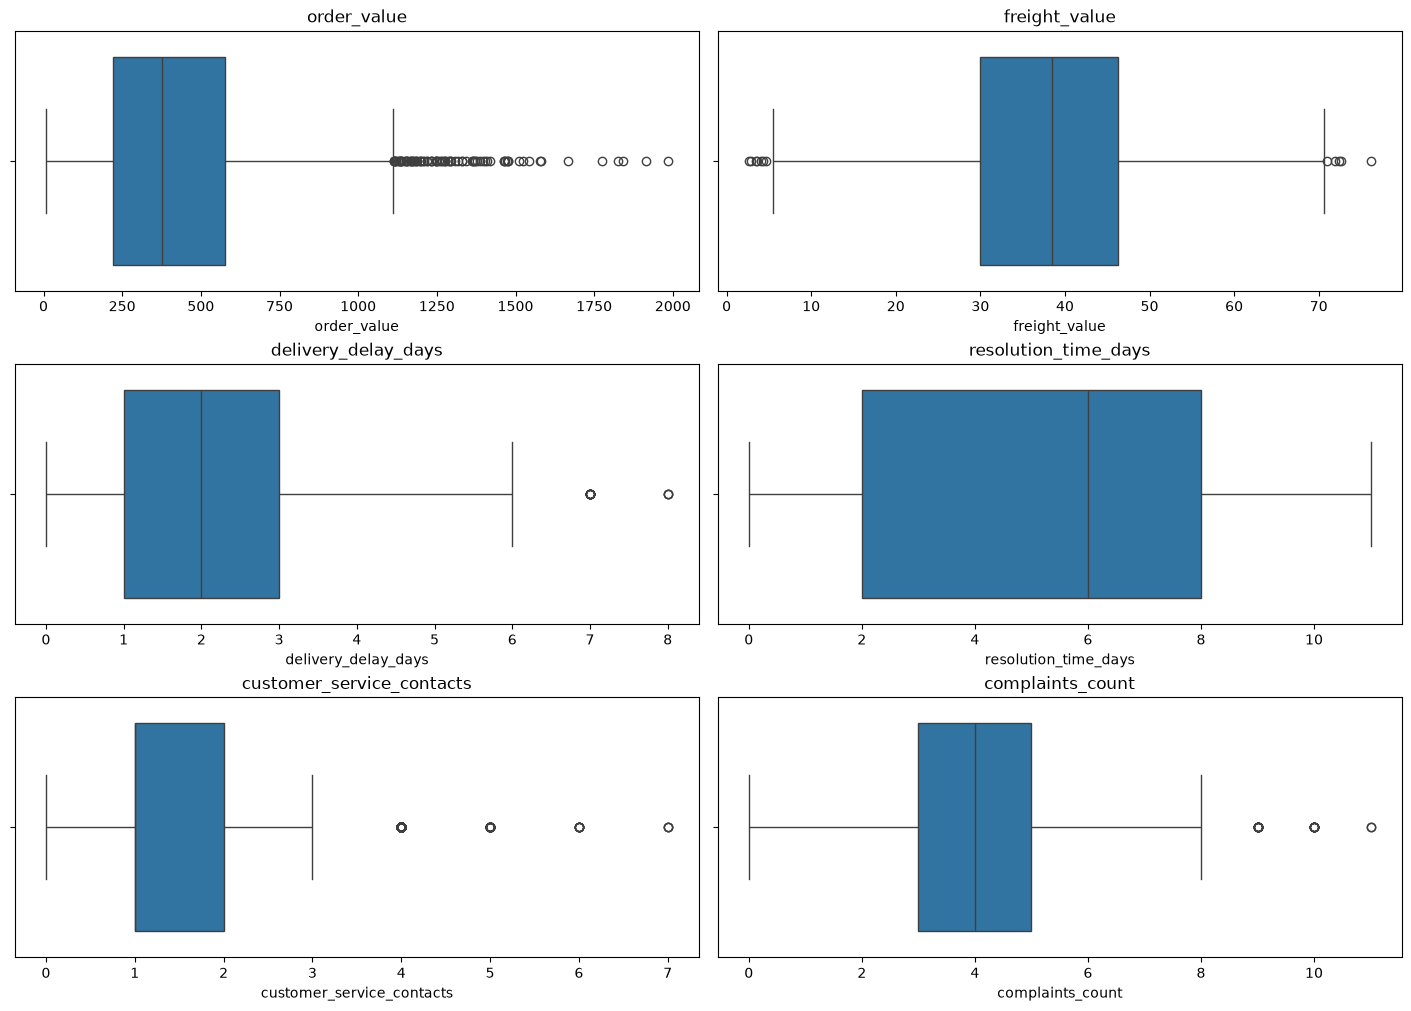

In [12]:
variaveis = [
    'order_value',
    'freight_value',
    'delivery_delay_days',
    'resolution_time_days',
    'customer_service_contacts',
    'complaints_count'
]

fig, axs = plt.subplots(
    3, 2,
    figsize=(14, 10),
    layout='constrained'
)

for ax, coluna in zip(axs.flat, variaveis):
    sns.boxplot(data=df, x=coluna, ax=ax)
    ax.set_title(coluna)

plt.show()

In [13]:
resultado = []

for coluna in variaveis:
    valores = df[coluna].dropna()

    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    outliers = (valores < inferior) | (valores > superior)

    resultado.append({
        'variavel': coluna,
        'limite_inferior': inferior,
        'limite_superior': superior,
        'quantidade_outliers': outliers.sum(),
        'percentual_outliers': outliers.mean() * 100,
        'IQR': iqr
    })

tabela_outliers = pd.DataFrame(resultado)

display(tabela_outliers.round(2))

,variavel,limite_inferior,limite_superior,quantidade_outliers,percentual_outliers,IQR
0,order_value,-315.32,1112.86,84,3.36,357.04
1,freight_value,5.41,70.78,12,0.48,16.34
2,delivery_delay_days,-2.00,6.00,17,0.68,2.00
3,resolution_time_days,-7.00,17.00,0,0.00,6.00
4,customer_service_contacts,-0.50,3.50,176,7.04,1.00
5,complaints_count,0.00,8.00,29,1.16,2.00


### Análise de valores extremos e possíveis outliers

A investigação pelo critério de 1,5 vez o intervalo interquartil (IQR) identificou registros com valores extremos em cinco das seis variáveis avaliadas. Esses registros representam ocorrências incomuns em relação à distribuição de cada variável, mas não constituem, necessariamente, erros de preenchimento.

A variável **número de contatos com o atendimento** apresentou a maior proporção de registros sinalizados: **176 casos (7,04%)**, correspondentes a quatro ou mais contatos. Esse resultado sugere a necessidade de investigar possíveis dificuldades na resolução das demandas e recorrência de problemas. Entretanto, a quantidade de contatos, isoladamente, não permite determinar suas causas.

Na variável **quantidade de reclamações**, foram identificados **29 registros (1,16%)** com nove ou mais reclamações. Esses casos podem representar experiências com maior acúmulo de atritos. Recomenda-se verificar sua relação com o número de contatos, o tempo de resolução e a classificação NPS.

Em relação ao **atraso na entrega**, foram sinalizados **17 registros (0,68%)** com atrasos superiores a seis dias. Embora pouco frequentes, esses episódios merecem investigação por representarem situações extremas na operação logística. Ressalta-se que atrasos dentro dos limites estatísticos também podem comprometer a satisfação: a ausência de classificação como outlier não significa que o prazo seja adequado à expectativa do cliente.

O **valor dos pedidos** apresentou **84 registros sinalizados (3,36%)**, correspondentes a pedidos superiores a aproximadamente **1.112,86**. Valores elevados podem representar compras legítimas, sendo relevante investigar sua participação no faturamento e a experiência associada a esses pedidos.

No **valor do frete**, foram encontrados **12 registros sinalizados (0,48%)**, abaixo de aproximadamente **5,41** ou acima de **70,78**. A análise deve distinguir esses dois grupos, pois valores reduzidos e elevados podem estar associados a condições comerciais e operacionais diferentes.

O **tempo de resolução** não apresentou registros fora dos limites calculados. Esse resultado indica apenas a ausência de outliers pelo critério adotado, não sendo suficiente para concluir que os prazos de atendimento sejam satisfatórios.

**Implicações para a análise**

Os resultados orientam o aprofundamento da investigação sobre contatos recorrentes, reclamações e atrasos extremos, relacionando essas ocorrências ao NPS e à recompra. A sinalização estatística, isoladamente, não justifica a exclusão dos registros: é necessário distinguir inconsistências de dados de situações reais e relevantes para o negócio.

Os limites do IQR não devem ser interpretados como metas operacionais. Além disso, as quantidades e os percentuais apresentados não devem ser somados para estimar o total de registros afetados, pois um mesmo registro pode ser sinalizado em mais de uma variável.

# 2.1 Qual é a distribuição dos clientes entre detratores, neutros e promotores?

In [14]:
def classificador_nps(df):
    if df['nps_score']>=9:
        return 'Promotores'
    elif df['nps_score']>=7:
        return 'Neutro'
    else:
        return 'Detrator'

In [15]:
df['clas_cliente'] = df.apply(classificador_nps, axis=1)

In [16]:
df[['clas_cliente', 'nps_score']].head(10)

,clas_cliente,nps_score
0,Neutro,7
1,Detrator,2
2,Detrator,5
3,Detrator,6
4,Detrator,6
5,Detrator,1
6,Detrator,1
7,Detrator,0
8,Detrator,6
9,Detrator,3


In [17]:
#proporção de clientes detratores, neutros e promotores
prop_clientes=df['clas_cliente'].value_counts()/len(df)*100

In [18]:
prop_clientes

clas_cliente
Detrator      80.04
Neutro        14.04
Promotores     5.92
Name: count, dtype: float64

In [19]:
#numero de clientes detratores, neutros e promotores
df['clas_cliente'].value_counts()

clas_cliente
Detrator      2001
Neutro         351
Promotores     148
Name: count, dtype: int64

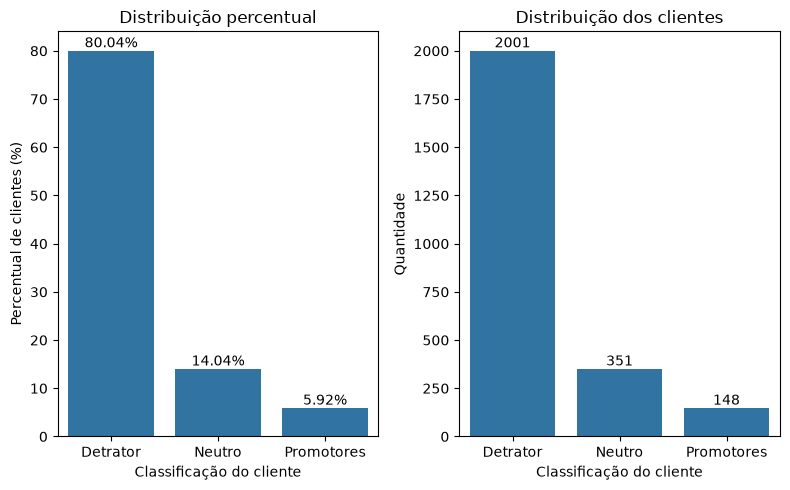

In [20]:
fig, ax = plt.subplots(1,2, figsize=(8,5))

sns.barplot(
  data = (
    df['clas_cliente']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index(name='percentual')
  ),
  x = 'clas_cliente',
  y='percentual',
  ax=ax[0]
)


ax[0].set_title('Distribuição percentual')
ax[0].set_xlabel('Classificação do cliente')
ax[0].set_ylabel('Percentual de clientes (%)')

for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.2f%%')

sns.barplot(
  data = (
    df['clas_cliente']
    .value_counts()
    .rename_axis('clas_cliente')
    .reset_index(name='quantidade')
  ),
  x = 'clas_cliente',
  y='quantidade',
  ax=ax[1]
)


ax[1].set_title('Distribuição dos clientes')
ax[1].set_xlabel('Classificação do cliente')
ax[1].set_ylabel('Quantidade')
for container in ax[1].containers:
    ax[1].bar_label(container)

plt.tight_layout()
plt.show()

**Análise**

A base apresenta 80,04% de detratores, 14,04% de neutros e 5,92% de promotores. O NPS é de **−74,12**.

A predominância de detratores mostra um cenário de baixa satisfação entre os clientes analisados. Nas próximas etapas, serão investigados os indicadores de entrega e atendimento para entender quais apresentam maior relação com esse resultado.

### Ticket médio por classificação NPS

Nesta etapa, será comparado o valor médio dos pedidos entre
detratores, neutros e promotores.

In [68]:
ticket_medio = (
    df.groupby('clas_cliente')['order_value']
    .mean()
    .reindex(['Detrator', 'Neutro', 'Promotores'])
    .round(2)
)

ticket_medio

clas_cliente
Detrator      429.69
Neutro        452.70
Promotores    452.30
Name: order_value, dtype: float64

**Análise**

Os tickets médios apresentam valores próximos entre as classificações
NPS, sem uma diferença descritiva expressiva. Nesta amostra, o valor
médio do pedido diferencia pouco os grupos de satisfação.

Esse resultado direciona o aprofundamento para aspectos da experiência
de compra, como entrega e atendimento. Entretanto, a proximidade das
médias não demonstra que o valor do pedido seja irrelevante em todos
os segmentos.

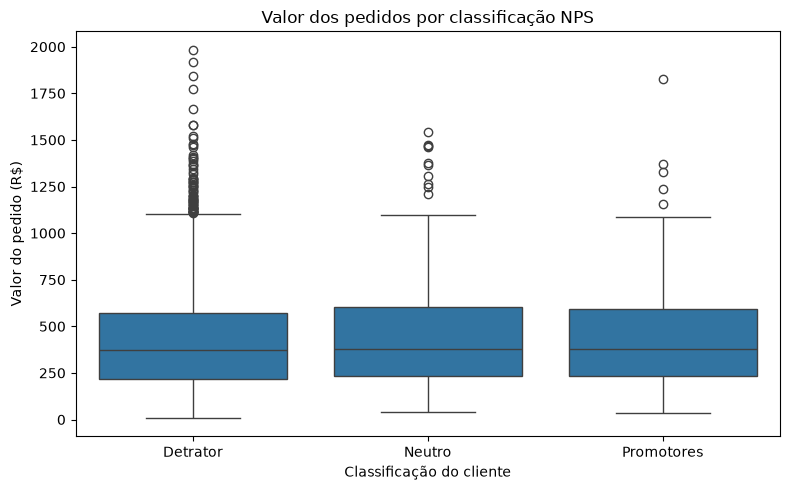

In [69]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='clas_cliente',
    y='order_value',
    order=['Detrator', 'Neutro', 'Promotores'],
    ax=ax
)

ax.set_title('Valor dos pedidos por classificação NPS')
ax.set_xlabel('Classificação do cliente')
ax.set_ylabel('Valor do pedido (R$)')

plt.tight_layout()
plt.show()

**Análise**

Os boxplots apresentam medianas próximas e ampla sobreposição das
caixas entre detratores, neutros e promotores. Isso indica semelhança
nos valores típicos dos pedidos, complementando a comparação dos
tickets médios.

Há pedidos de valor elevado sinalizados como possíveis outliers nas
três classificações. A maior quantidade visual entre detratores deve
ser interpretada considerando que esse grupo também concentra a
maior parte dos registros da base.

Esses valores não representam necessariamente erros: podem ser compras
legítimas de maior valor. Sua presença recomenda comparar média e
mediana, pois o ticket médio pode ser influenciado por essas compras.
O gráfico, isoladamente, não indica que pedidos de maior valor estejam
associados a uma classificação NPS específica.

# 2.2 Matriz de correlação das variáveis numéricas

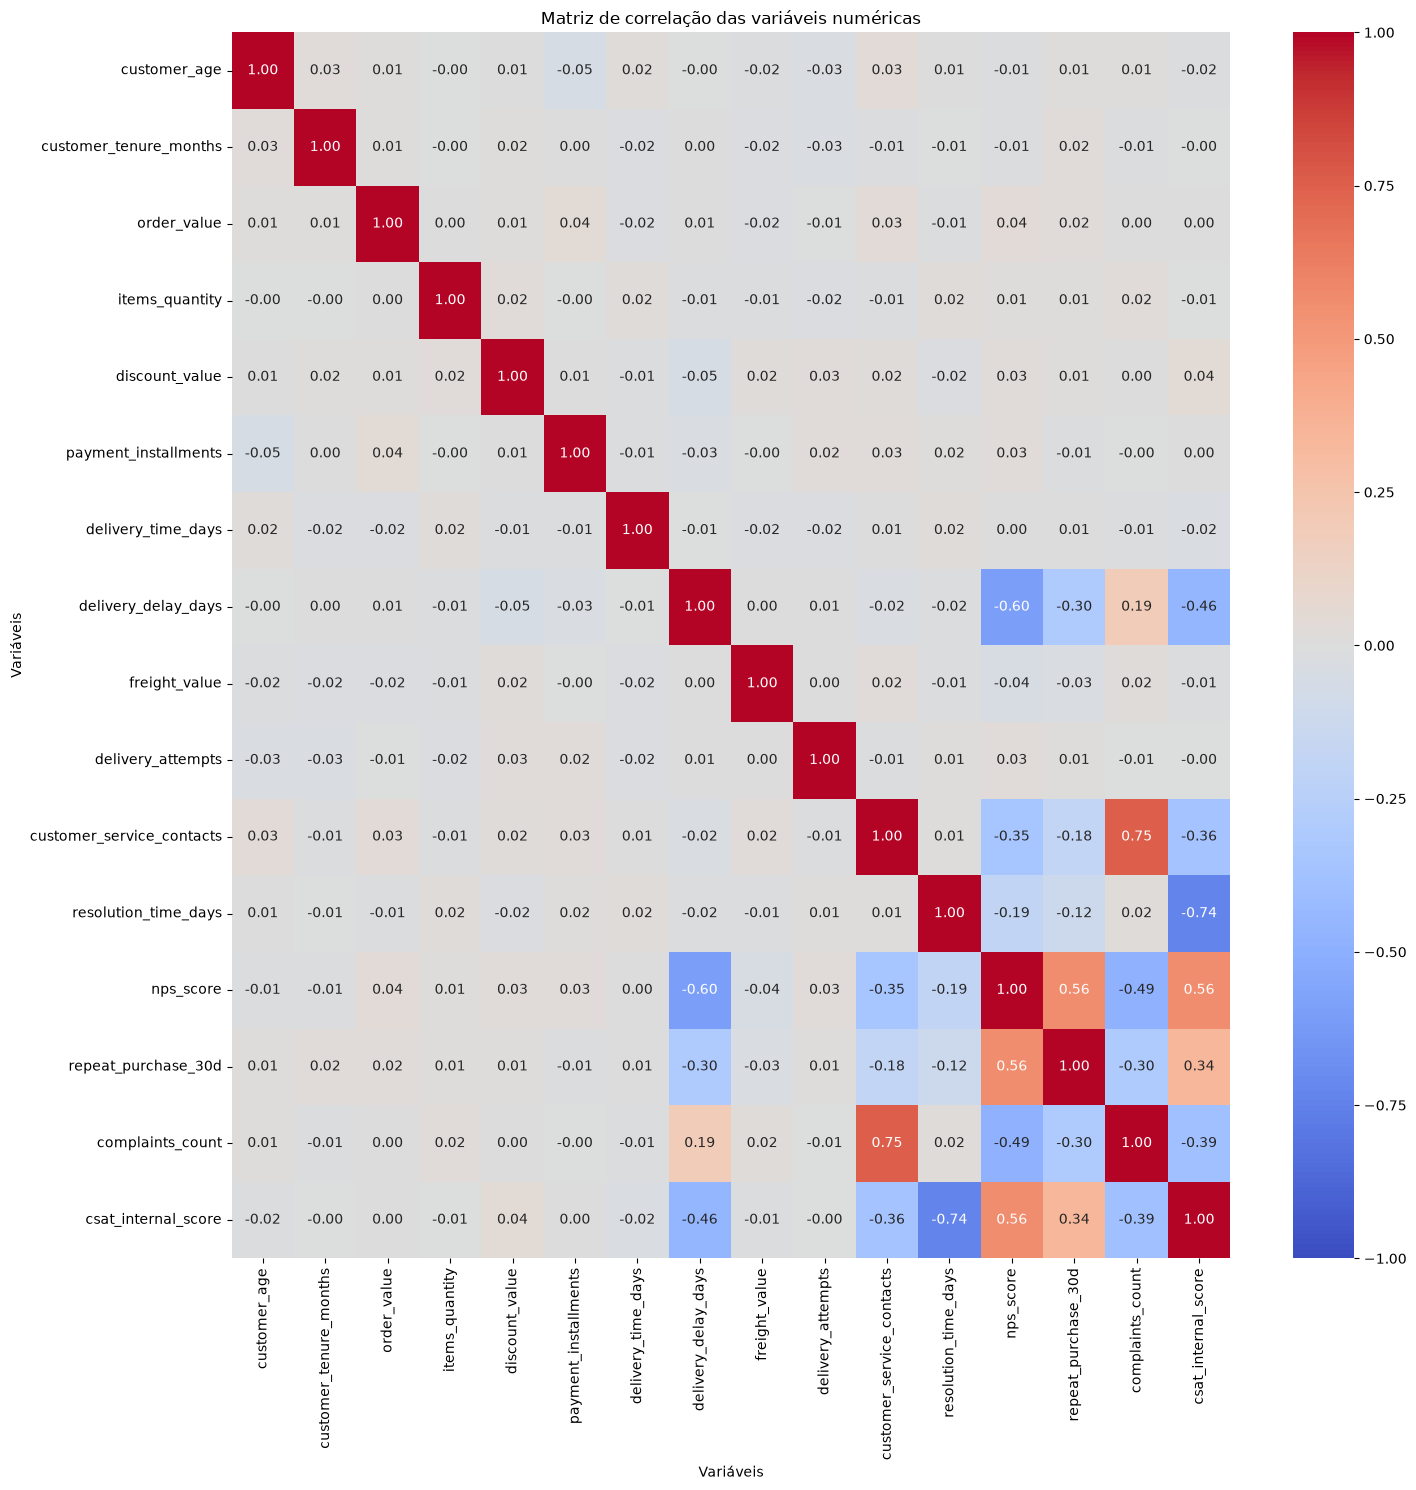

In [21]:
plt.figure(figsize=(15, 15))

sns.heatmap(
    df.drop(columns=['customer_id', 'order_id', 'nps_score_original']).corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação das variáveis numéricas")
plt.xlabel("Variáveis")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

**Análise**

O NPS apresenta associação negativa com atraso, reclamações e contatos com atendimento. O tempo de resolução também tem associação negativa, mas de menor intensidade. Os valores exatos estão na matriz acima.

O CSAT acompanha o NPS porque também avalia satisfação. Para entender os problemas da jornada, faz mais sentido aprofundar os indicadores operacionais. A recompra será analisada separadamente.

Os outliers de atraso, contatos e reclamações merecem atenção, mas a correlação da base inteira não mostra se eles explicam a relação observada. Por isso, os registros com e sem outliers serão comparados na seção 3.

## 2.3 Distribuição das variáveis por classificação NPS

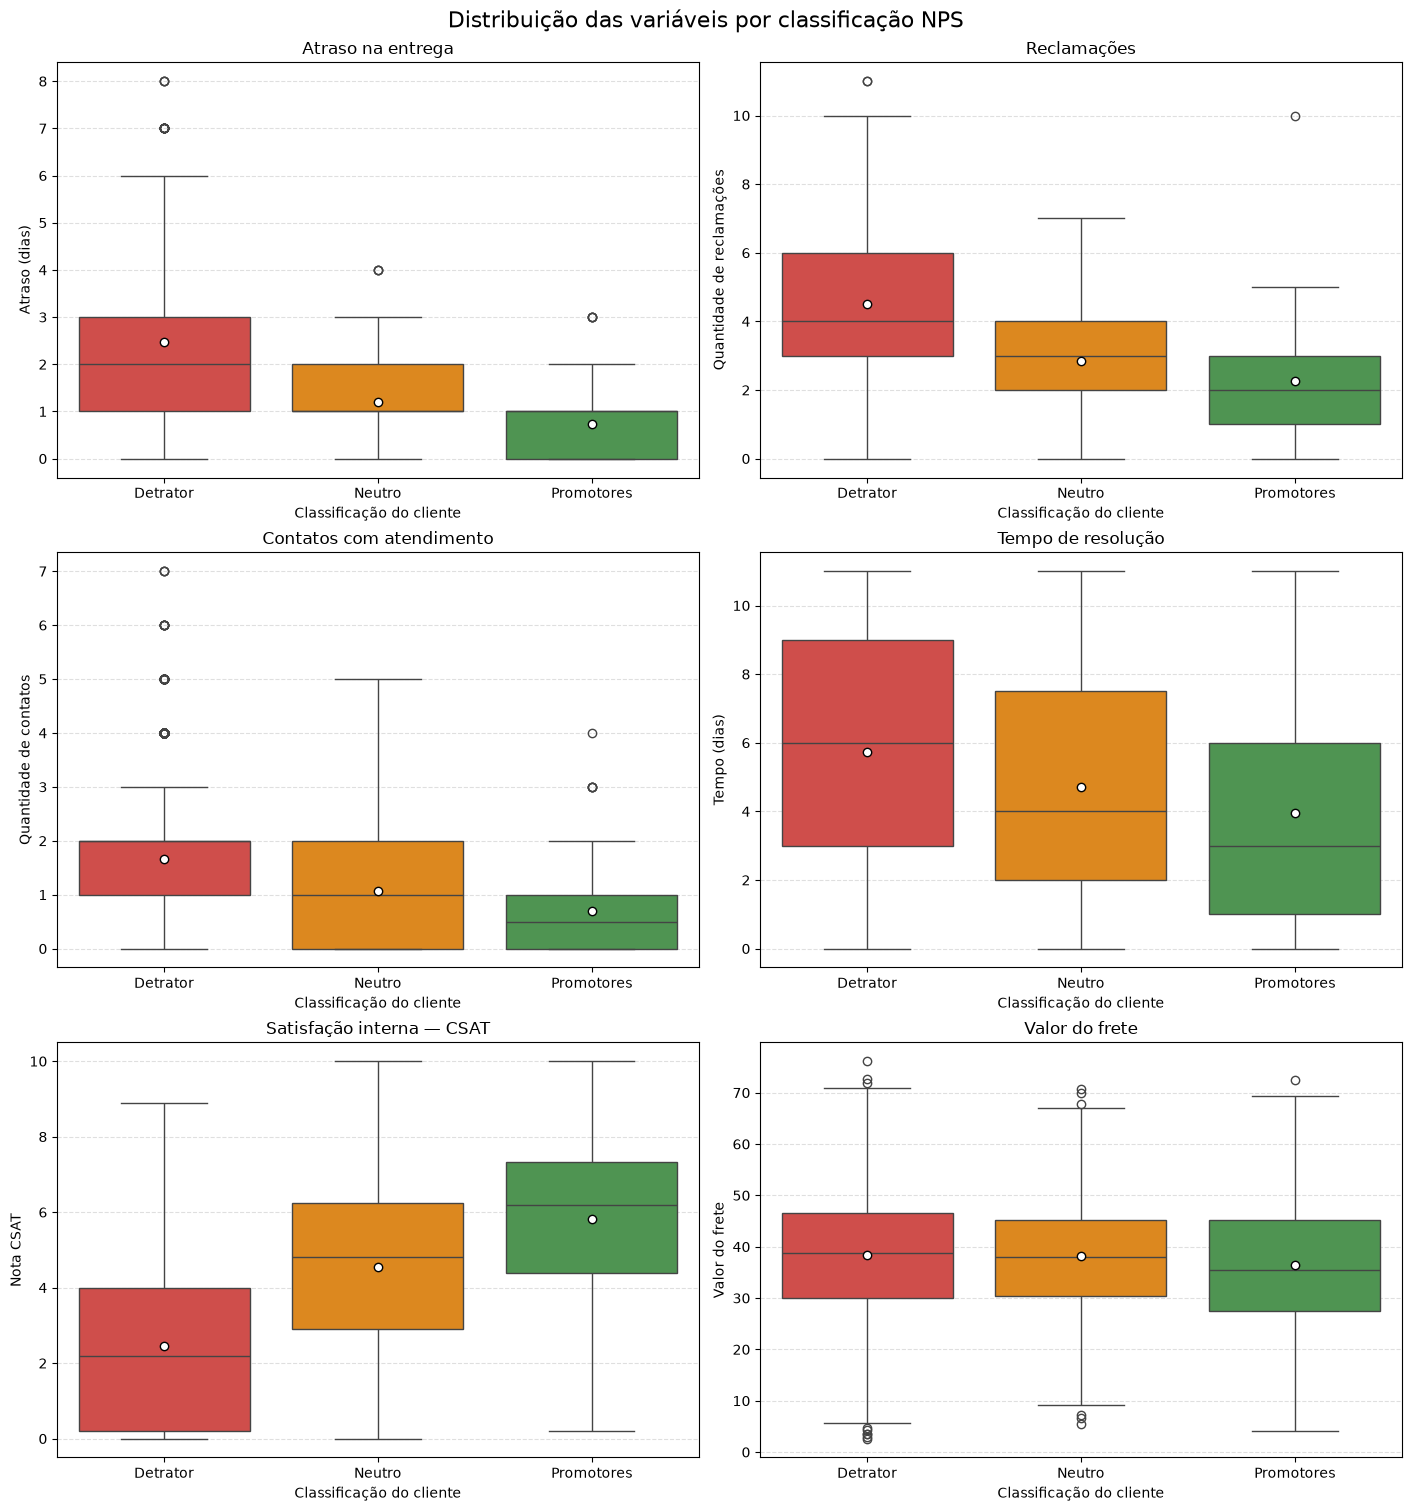

In [22]:
# Ordem e cores das classificações
ordem = ['Detrator', 'Neutro', 'Promotores']

cores = {
    'Detrator': '#E53935',
    'Neutro': '#FB8C00',
    'Promotores': '#43A047'
}

# Variável, título e nome do eixo vertical
variaveis = [
    ('delivery_delay_days', 'Atraso na entrega', 'Atraso (dias)'),
    ('complaints_count', 'Reclamações', 'Quantidade de reclamações'),
    ('customer_service_contacts', 'Contatos com atendimento', 'Quantidade de contatos'),
    ('resolution_time_days', 'Tempo de resolução', 'Tempo (dias)'),
    ('csat_internal_score', 'Satisfação interna — CSAT', 'Nota CSAT'),
    ('freight_value', 'Valor do frete', 'Valor do frete')
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 15),
    layout='constrained'
)

for ax, (coluna, titulo, rotulo_y) in zip(axes.flat, variaveis):
    sns.boxplot(
        data=df,
        x='clas_cliente',
        y=coluna,
        order=ordem,
        hue='clas_cliente',
        hue_order=ordem,
        palette=cores,
        dodge=False,
        legend=False,
        showmeans=True,
        meanprops={
            'marker': 'o',
            'markerfacecolor': 'white',
            'markeredgecolor': 'black'
        },
        ax=ax
    )

    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel('Classificação do cliente')
    ax.set_ylabel(rotulo_y)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_axisbelow(True)

fig.suptitle(
    'Distribuição das variáveis por classificação NPS',
    fontsize=16
)

plt.show()

**Análise dos boxplots**

O atraso apresenta diferenças tanto na média quanto na mediana. Entre detratores, o atraso médio é de 2,47 dias e a mediana é de 2 dias; entre promotores, são 0,73 e 1 dia. Isso mostra que a diferença não depende apenas de alguns atrasos extremos: ela também aparece na experiência típica dos grupos.

Nas reclamações, as medianas são de 4 entre detratores, 3 entre neutros e 2 entre promotores. As médias seguem a mesma direção: 4,52, 2,85 e 2,26. Os promotores também apresentam reclamações, portanto sua existência não determina sozinha uma avaliação negativa. Vale investigar o motivo, a gravidade e o resultado da resolução dessas demandas.

Nos contatos, os detratores apresentam média de 1,66 e mediana de 2, enquanto os promotores apresentam média de 0,70 e mediana de 0,5. A necessidade de interações repetidas diferencia os grupos, mas pode representar uma consequência de problemas anteriores na compra.

O tempo de resolução tem mediana de 6 dias entre detratores, 4 entre neutros e 3 entre promotores. A sobreposição das caixas mostra que há experiências com prazos semelhantes e avaliações diferentes. Assim, o prazo merece acompanhamento, mas não resume a qualidade da solução recebida.

No CSAT, as médias aumentam de 2,45 entre detratores para 4,54 entre neutros e 5,83 entre promotores. A direção é coerente com o NPS. Já o frete tem médias de 38,35, 38,16 e 36,52, com maior proximidade entre os grupos. Nesta comparação, o atendimento e a entrega diferenciam mais as classificações do que o valor do frete.

Os círculos brancos representam as médias. Os pontos extremos são definidos dentro de cada classe e não devem ser confundidos com os outliers da base completa.

# 2.4 One-Hot Encoding da classificação NPS para entender a relação dos tipos de clientes com as demais variaveis

In [23]:
from sklearn.preprocessing import OneHotEncoder

In [24]:
# Instanciando o encoder
encoder = OneHotEncoder(
    sparse_output=False,
    dtype=int
)

In [25]:
# Aplicando One-Hot Encoding
encoded = encoder.fit_transform(df[['clas_cliente','customer_region']])

In [26]:
encoder.get_feature_names_out()

array(['clas_cliente_Detrator', 'clas_cliente_Neutro',
       'clas_cliente_Promotores', 'customer_region_Centro-Oeste',
       'customer_region_Nordeste', 'customer_region_Norte',
       'customer_region_Sudeste', 'customer_region_Sul'], dtype=object)

In [27]:
# Transformando o resultado em DataFrame
df_encoded = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(),
    index=df.index
)

In [28]:
# Remove as colunas do encoding caso já existam
df = df.drop(
    columns=df_encoded.columns,
    errors='ignore'
)


# Adicionando as novas variáveis ao dataset
df = pd.concat(
    [df, df_encoded],
    axis=1
)

In [29]:
df_corr_clas_cliente = df.corr(numeric_only=True)[['clas_cliente_Detrator', 'clas_cliente_Neutro',
       'clas_cliente_Promotores']]

In [30]:
df_corr_clas_cliente = df_corr_clas_cliente[
    df_corr_clas_cliente.abs().max(axis=1) >= 0.10
]

In [31]:
df_corr_clas_cliente = df_corr_clas_cliente.drop(
    index=[
        'nps_score',
        'nps_score_original',
        'customer_id',
        'order_id',
        'clas_cliente_Detrator',
        'clas_cliente_Neutro',
        'clas_cliente_Promotores'
    ],
    errors='ignore'
)

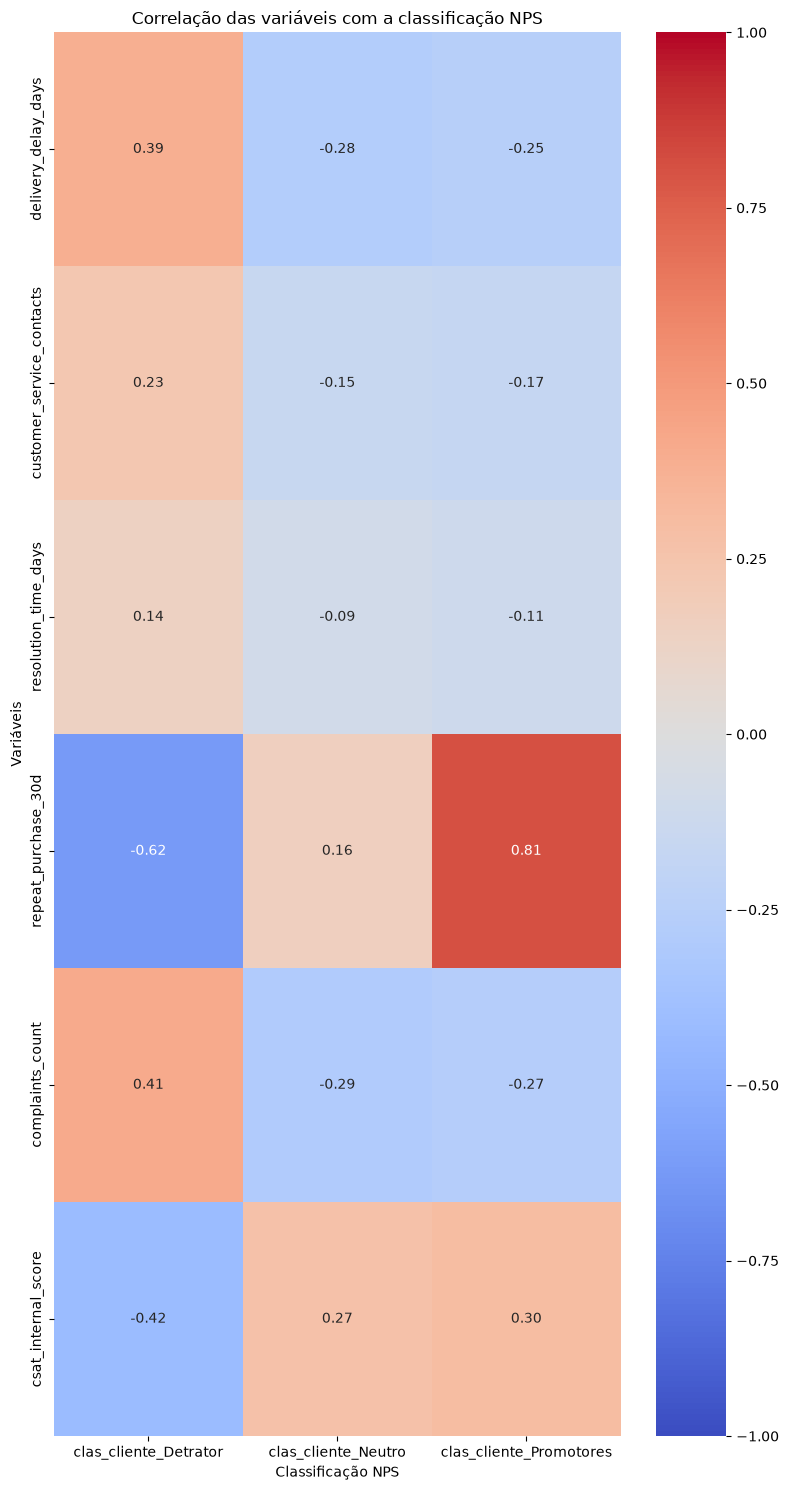

In [32]:
plt.figure(figsize=(8, 15))

sns.heatmap(
    df_corr_clas_cliente,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação das variáveis com a classificação NPS")
plt.xlabel("Classificação NPS")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

**Análise**

O segundo heatmap relaciona as variáveis à presença de cada classificação NPS. Reclamações, atraso e contatos acompanham a classificação como detrator; CSAT e recompra apresentam relação na direção contrária.

Esse resultado complementa a correlação com a nota. A filtragem exibe apenas variáveis que atingem correlação absoluta de pelo menos 0,10 com alguma classe; as demais não devem ser interpretadas como inexistentes ou necessariamente irrelevantes.

# 2.5 Como o atraso se distribui entre as classificações NPS?

In [33]:
df_detratores = df[df['clas_cliente'] == 'Detrator']
df_neutros = df[df['clas_cliente'] == 'Neutro']
df_promotores = df[df['clas_cliente'] == 'Promotores']

contagem_detratores = (
    df_detratores['delivery_delay_days']
    .value_counts()
    .sort_index()
)

contagem_neutros = (
    df_neutros['delivery_delay_days']
    .value_counts()
    .sort_index()
)

contagem_promotores = (
    df_promotores['delivery_delay_days']
    .value_counts()
    .sort_index()
)

In [34]:
distrib_atraso = pd.crosstab(
    df['delivery_delay_days'],
    df['clas_cliente'],
    normalize='columns'
).mul(100).round(1)

distrib_atraso

clas_cliente,Detrator,Neutro,Promotores
delivery_delay_days,,,
0,6.2,24.5,44.6
1,20.5,41.0,40.5
2,26.8,25.9,12.2
3,24.7,7.7,2.7
4,13.3,0.9,0.0
5,5.8,0.0,0.0
6,1.7,0.0,0.0
7,0.7,0.0,0.0
8,0.1,0.0,0.0


In [35]:
df['faixa_atraso'] = df['delivery_delay_days'].apply(
    lambda x: 'Até 1 dia' if x <= 1 else '2 dias ou mais'
)

In [36]:
contagem_detratores = (
    df[df['clas_cliente'] == 'Detrator']['faixa_atraso']
    .value_counts(normalize=True)
    .mul(100)
    .reindex(['Até 1 dia', '2 dias ou mais'])
)

contagem_neutros = (
    df[df['clas_cliente'] == 'Neutro']['faixa_atraso']
    .value_counts(normalize=True)
    .mul(100)
    .reindex(['Até 1 dia', '2 dias ou mais'])
)

contagem_promotores = (
    df[df['clas_cliente'] == 'Promotores']['faixa_atraso']
    .value_counts(normalize=True)
    .mul(100)
    .reindex(['Até 1 dia', '2 dias ou mais'])
)

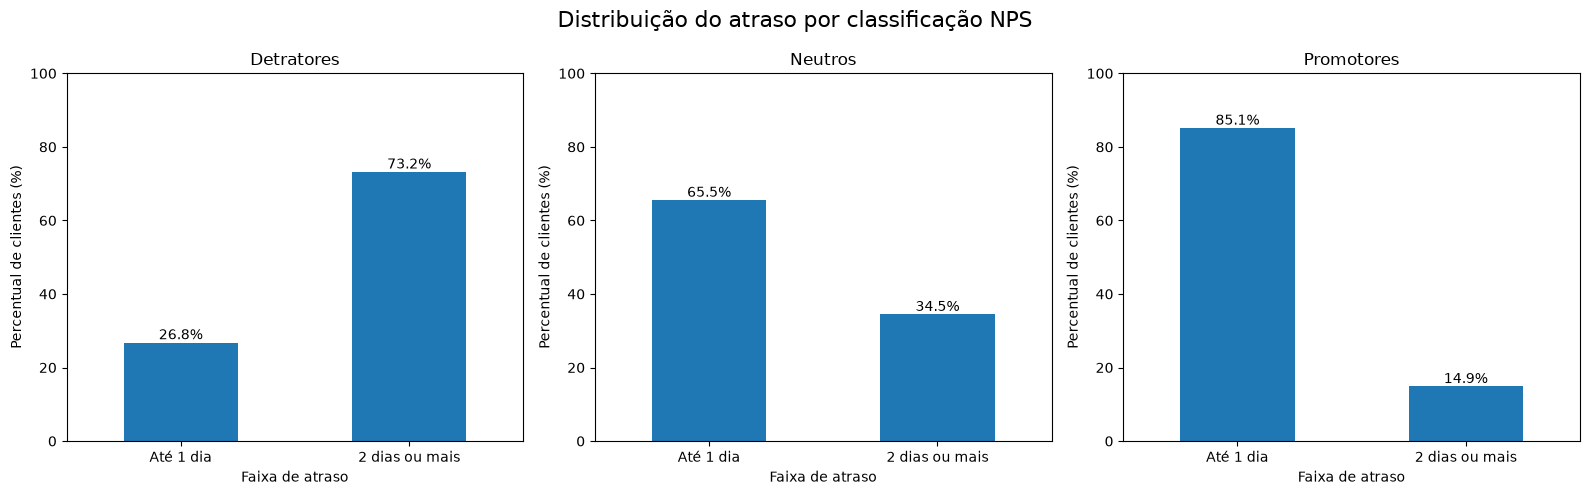

In [37]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# Detratores
contagem_detratores.plot(
    kind='bar',
    ax=axs[0]
)

axs[0].set_title('Detratores')
axs[0].set_xlabel('Faixa de atraso')
axs[0].set_ylabel('Percentual de clientes (%)')
axs[0].tick_params(axis='x', rotation=0)
axs[0].set_ylim(0, 100)


# Neutros
contagem_neutros.plot(
    kind='bar',
    ax=axs[1]
)

axs[1].set_title('Neutros')
axs[1].set_xlabel('Faixa de atraso')
axs[1].set_ylabel('Percentual de clientes (%)')
axs[1].tick_params(axis='x', rotation=0)
axs[1].set_ylim(0, 100)


# Promotores
contagem_promotores.plot(
    kind='bar',
    ax=axs[2]
)

axs[2].set_title('Promotores')
axs[2].set_xlabel('Faixa de atraso')
axs[2].set_ylabel('Percentual de clientes (%)')
axs[2].tick_params(axis='x', rotation=0)
axs[2].set_ylim(0, 100)


# Rótulos em todos os gráficos
for ax in axs:
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.1f%%'
        )


fig.suptitle(
    'Distribuição do atraso por classificação NPS',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Análise**

Entre os promotores, 85,14% tiveram até um dia de atraso. Entre neutros, esse percentual é de 65,53%; entre detratores, de apenas 26,79%. Por outro lado, 73,21% dos detratores tiveram pelo menos dois dias de atraso, contra 14,86% dos promotores.

A diferença mostra que entregas com atrasos menores são mais frequentes entre os clientes de maior satisfação. A participação de atrasos de dois dias ou mais é cerca de cinco vezes maior dentro dos detratores do que dentro dos promotores. Essa comparação descreve os perfis; não significa que atrasar dois dias multiplique por cinco a chance de ser detrator.

Também há detratores com atrasos pequenos e promotores com atrasos maiores. Portanto, a entrega é relevante, mas não explica todas as avaliações. A próxima etapa compara atendimento e reclamações para investigar outros atritos.

# 2.6 Atendimento e reclamações por classificação NPS

In [38]:
df_detratores = df[df['clas_cliente'] == 'Detrator'].copy()

df_detratores['faixa_atraso'] = df_detratores['delivery_delay_days'].apply(
    lambda x: 'Até 1 dia' if x <= 1 else '2 dias ou mais'
)

In [39]:
df_detratores['faixa_atraso'].value_counts()

faixa_atraso
2 dias ou mais    1465
Até 1 dia          536
Name: count, dtype: int64

In [40]:
analise_detratores = (
    df_detratores
    .groupby('faixa_atraso')[
        [
            'resolution_time_days',
            'customer_service_contacts',
            'complaints_count'
        ]
    ]
    .mean()
    .round(2)
)

analise_detratores

,resolution_time_days,customer_service_contacts,complaints_count
faixa_atraso,,,
2 dias ou mais,5.57,1.58,4.52
Até 1 dia,6.18,1.89,4.52


In [41]:
analise_classes = (
    df.groupby('clas_cliente')[
        [
            'resolution_time_days',
            'customer_service_contacts',
            'complaints_count'
        ]
    ]
    .mean()
    .round(2)
)

analise_classes

,resolution_time_days,customer_service_contacts,complaints_count
clas_cliente,,,
Detrator,5.73,1.66,4.52
Neutro,4.72,1.07,2.85
Promotores,3.95,0.70,2.26


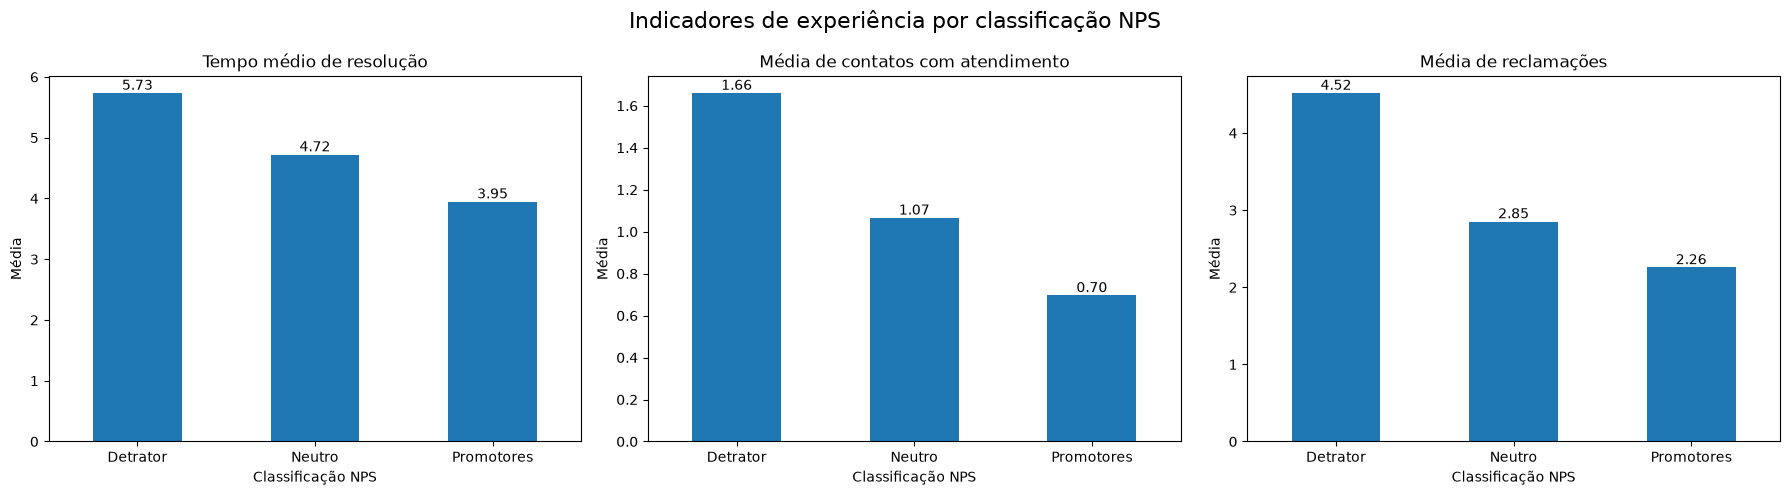

In [42]:
variaveis = [
    'resolution_time_days',
    'customer_service_contacts',
    'complaints_count'
]

titulos = [
    'Tempo médio de resolução',
    'Média de contatos com atendimento',
    'Média de reclamações'
]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for i, variavel in enumerate(variaveis):

    media = (
        df.groupby('clas_cliente')[variavel]
        .mean()
        .reindex(['Detrator', 'Neutro', 'Promotores'])
    )

    media.plot(
        kind='bar',
        ax=axs[i]
    )

    axs[i].set_title(titulos[i])
    axs[i].set_xlabel('Classificação NPS')
    axs[i].set_ylabel('Média')
    axs[i].tick_params(axis='x', rotation=0)

    for container in axs[i].containers:
        axs[i].bar_label(container, fmt='%.2f')

fig.suptitle(
    'Indicadores de experiência por classificação NPS',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Análise**

As médias por classificação mostram um padrão consistente: detratores apresentam 5,73 dias de resolução, 1,66 contatos e 4,52 reclamações. Entre neutros, são 4,72 dias, 1,07 contatos e 2,85 reclamações. Entre promotores, são 3,95 dias, 0,70 contatos e 2,26 reclamações.

Entretanto, a comparação apenas entre detratores por faixa de atraso traz uma informação importante. Os detratores com até um dia de atraso apresentam resolução média de 6,18 dias e 1,89 contatos; aqueles com dois dias ou mais apresentam 5,57 dias e 1,58 contatos. A média de reclamações é praticamente igual: 4,52 nos dois grupos.

Assim, não aparece uma piora simultânea de todos os indicadores conforme o atraso aumenta dentro dos detratores. Há sinais de perfis distintos de insatisfação: parte enfrenta maior atraso; outra parte apresenta atrasos menores, mas mais contatos e resolução mais demorada. Isso impede atribuir toda a insatisfação à logística e justifica investigar a jornada de atendimento separadamente.

Essa comparação descreve apenas os clientes já classificados como detratores. Não demonstra que um fator compense outro ou que os problemas sejam independentes.

# 2.7 Distribuição do tempo de resolução, contatos e reclamações

### 2.7.1 Tempo de resolução

In [43]:
ruptura_resolution = pd.crosstab(
    df['resolution_time_days'],
    df['clas_cliente'],
    normalize='columns'
).mul(100).round(1)

ruptura_resolution

clas_cliente,Detrator,Neutro,Promotores
resolution_time_days,,,
0,7.2,12.5,13.5
1,6.8,10.8,12.2
2,8.7,10.0,12.8
3,8.9,9.4,17.6
4,8.3,7.4,9.5
5,6.9,8.8,4.7
6,8.1,6.8,7.4
7,8.6,9.1,5.4
8,9.5,8.3,4.7


### 2.7.2 Contatos com atendimento

In [44]:
ruptura_contatos = pd.crosstab(
    df['customer_service_contacts'],
    df['clas_cliente'],
    normalize='columns'
).mul(100).round(1)

ruptura_contatos

clas_cliente,Detrator,Neutro,Promotores
customer_service_contacts,,,
0,18.2,33.0,50.0
1,31.6,37.6,34.5
2,27.4,21.1,12.2
3,14.3,6.6,2.7
4,6.3,1.4,0.7
5,1.6,0.3,0.0
6,0.3,0.0,0.0
7,0.1,0.0,0.0


### 2.7.3 Número de reclamações

In [45]:
ruptura_reclamacoes = pd.crosstab(
    df['complaints_count'],
    df['clas_cliente'],
    normalize='columns'
).mul(100).round(1)

ruptura_reclamacoes

clas_cliente,Detrator,Neutro,Promotores
complaints_count,,,
0,0.1,2.6,8.1
1,1.2,17.1,25.7
2,7.6,23.9,27.0
3,19.3,26.8,18.2
4,26.0,15.4,16.9
5,20.3,9.1,3.4
6,12.7,3.1,0.0
7,8.1,2.0,0.0
8,3.1,0.0,0.0


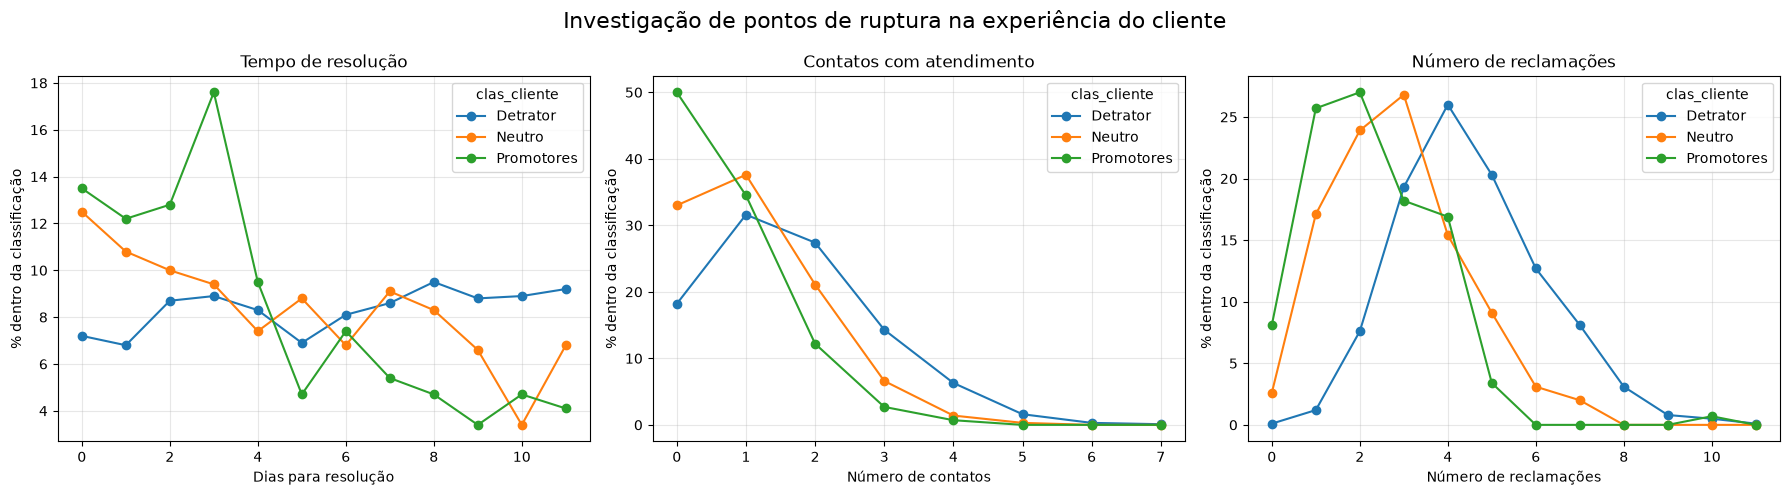

In [46]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))


# Tempo de resolução
ruptura_resolution.plot(
    kind='line',
    marker='o',
    ax=axs[0]
)

axs[0].set_title('Tempo de resolução')
axs[0].set_xlabel('Dias para resolução')
axs[0].set_ylabel('% dentro da classificação')
axs[0].grid(alpha=0.3)


# Contatos com atendimento
ruptura_contatos.plot(
    kind='line',
    marker='o',
    ax=axs[1]
)

axs[1].set_title('Contatos com atendimento')
axs[1].set_xlabel('Número de contatos')
axs[1].set_ylabel('% dentro da classificação')
axs[1].grid(alpha=0.3)


# Reclamações
ruptura_reclamacoes.plot(
    kind='line',
    marker='o',
    ax=axs[2]
)

axs[2].set_title('Número de reclamações')
axs[2].set_xlabel('Número de reclamações')
axs[2].set_ylabel('% dentro da classificação')
axs[2].grid(alpha=0.3)


fig.suptitle(
    'Investigação de pontos de ruptura na experiência do cliente',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Análise**

No tempo de resolução, 60,07% dos detratores apresentam cinco dias ou mais, contra 34,46% dos promotores. Apesar dessa diferença, as curvas se sobrepõem e apresentam oscilações. O resultado aponta prazos geralmente maiores entre detratores, sem uma ruptura clara em um único dia.

Nos contatos, 84,46% dos promotores realizam no máximo um contato, contra 49,83% dos detratores. Dois ou mais contatos aparecem em 50,17% dos detratores e em 15,54% dos promotores. A recorrência de contatos é, portanto, uma diferença importante entre os perfis. Uma queda da curva após um contato significa menor frequência de registros naquele número, não redução da chance de insatisfação.

Nas reclamações, 71,76% dos detratores acumulam quatro ou mais ocorrências, enquanto esse percentual é de 20,95% entre promotores. O deslocamento das distribuições reforça o interesse em acompanhar o acúmulo de demandas, e não apenas registrar se houve alguma reclamação.

As três comparações usam o total de cada classificação como denominador. Para propor faixas de acompanhamento, a seção seguinte inverte a pergunta: qual é o percentual de detratores entre os clientes de cada nível do indicador?

# 3. Dado determinado nível de atraso, reclamações, contatos ou tempo de resolução, qual é a proporção de detratores?

In [47]:
baseline_detratores = (
    df['clas_cliente']
    .eq('Detrator')
    .mean()
    * 100
)

baseline_detratores

np.float64(80.04)

## 3.1 Numero de reclamaçoes

In [48]:
ruptura_reclamacoes_2 = pd.crosstab(
    df['complaints_count'],
    df['clas_cliente'],
    normalize='index'
).mul(100).round(1)

ruptura_reclamacoes_2

clas_cliente,Detrator,Neutro,Promotores
complaints_count,,,
0,8.7,39.1,52.2
1,19.7,49.2,31.1
2,55.2,30.3,14.4
3,76.1,18.5,5.3
4,86.8,9.0,4.2
5,91.7,7.2,1.1
6,95.9,4.1,0.0
7,95.9,4.1,0.0
8,100.0,0.0,0.0


In [49]:
ruptura_reclamacoes_2['baseline_detratores'] = baseline_detratores

ruptura_reclamacoes_2['dif_baseline'] = (
    ruptura_reclamacoes_2['Detrator']
    - baseline_detratores
).round(1)

ruptura_reclamacoes_2

clas_cliente,Detrator,Neutro,Promotores,baseline_detratores,dif_baseline
complaints_count,,,,,
0,8.7,39.1,52.2,80.04,-71.3
1,19.7,49.2,31.1,80.04,-60.3
2,55.2,30.3,14.4,80.04,-24.8
3,76.1,18.5,5.3,80.04,-3.9
4,86.8,9.0,4.2,80.04,6.8
5,91.7,7.2,1.1,80.04,11.7
6,95.9,4.1,0.0,80.04,15.9
7,95.9,4.1,0.0,80.04,15.9
8,100.0,0.0,0.0,80.04,20.0


**Análise**

A proporção de detratores cresce de 19,67% com uma reclamação para 55,23% com duas, 76,13% com três e 86,83% com quatro. O aumento entre uma e duas reclamações merece atenção.

Quatro reclamações já apresentam uma proporção superior aos 80,04% da base, mas superar essa referência não comprova um ponto de ruptura. As quantidades por faixa devem ser consideradas, principalmente nos valores extremos.

## 3.2 Contatos com atendimento

In [50]:
# Proporção das classificações para cada número de contatos
ruptura_contatos_2 = pd.crosstab(
    df['customer_service_contacts'],
    df['clas_cliente'],
    normalize='index'
).mul(100).round(1)

# Baseline geral de detratores
baseline_detratores = (
    df['clas_cliente']
    .eq('Detrator')
    .mean()
    * 100
)

# Adicionando baseline
ruptura_contatos_2['baseline_detratores'] = baseline_detratores

# Diferença em relação ao baseline
ruptura_contatos_2['dif_baseline'] = (
    ruptura_contatos_2['Detrator']
    - baseline_detratores
).round(1)

ruptura_contatos_2

clas_cliente,Detrator,Neutro,Promotores,baseline_detratores,dif_baseline
customer_service_contacts,,,,,
0,65.7,20.9,13.4,80.04,-14.3
1,77.6,16.2,6.2,80.04,-2.4
2,85.6,11.6,2.8,80.04,5.6
3,91.4,7.3,1.3,80.04,11.4
4,95.5,3.8,0.8,80.04,15.5
5,97.1,2.9,0.0,80.04,17.1
6,100.0,0.0,0.0,80.04,20.0
7,100.0,0.0,0.0,80.04,20.0


**Análise dos contatos**

A proporção de detratores cresce de 65,70% sem contato para 77,57% com um, 85,62% com dois e 91,40% com três. Mesmo entre clientes que não procuram atendimento, a maioria é detratora. Isso mostra que o contato não é uma condição necessária para a insatisfação e que a ausência de procura não garante uma boa experiência.

Dois contatos podem ser uma faixa candidata a acompanhamento, pois a proporção supera os 80,04% da base. Esse critério, porém, não comprova uma ruptura. Os percentuais mais extremos também têm pouca sustentação numérica: seis contatos envolvem sete registros, e sete contatos envolvem três.

Uma ação de negócio a testar seria verificar, no segundo contato, se o cliente está retornando pelo mesmo problema e se a solução anterior foi efetiva.

## 3.3 Tempo de resolução

In [51]:
ruptura_resolution_2 = pd.crosstab(
    df['resolution_time_days'],
    df['clas_cliente'],
    normalize='index'
).mul(100).round(1)

ruptura_resolution_2['baseline_detratores'] = baseline_detratores

ruptura_resolution_2['dif_baseline'] = (
    ruptura_resolution_2['Detrator']
    - baseline_detratores
).round(1)

ruptura_resolution_2

clas_cliente,Detrator,Neutro,Promotores,baseline_detratores,dif_baseline
resolution_time_days,,,,,
0,69.2,21.2,9.6,80.04,-10.8
1,70.8,19.8,9.4,80.04,-9.2
2,76.4,15.3,8.3,80.04,-3.6
3,75.1,13.9,11.0,80.04,-4.9
4,80.6,12.6,6.8,80.04,0.6
5,78.4,17.6,4.0,80.04,-1.6
6,82.2,12.2,5.6,80.04,2.2
7,81.2,15.0,3.8,80.04,1.2
8,84.1,12.8,3.1,80.04,4.1


**Análise do tempo de resolução**

Os percentuais são de 69,23% de detratores com zero dia, 75,11% com três, 80,58% com quatro e 78,41% com cinco. Depois, chegam a 86,27% com nove e 90,36% com dez dias, recuando para 85,98% com onze.

Há uma tendência geral de maior insatisfação nos prazos longos, mas não uma progressão estrita. A oscilação entre quatro e cinco dias enfraquece a escolha de um desses valores como ruptura. Além disso, o significado de resolução em zero dia deve ser confirmado: pode indicar solução imediata ou ausência de uma demanda aplicável.

O resultado favorece o acompanhamento de prazos e qualidade da solução em conjunto. A EDA não sustenta um prazo ideal de atendimento nem demonstra que reduzir o tempo, sozinho, resolva a insatisfação.

## 3.4 Atraso na entrega

In [52]:
ruptura_atraso_2 = pd.crosstab(
    df['delivery_delay_days'],
    df['clas_cliente'],
    normalize='index'
).mul(100).round(1)

ruptura_atraso_2['baseline_detratores'] = baseline_detratores

ruptura_atraso_2['dif_baseline'] = (
    ruptura_atraso_2['Detrator']
    - baseline_detratores
).round(1)

ruptura_atraso_2

clas_cliente,Detrator,Neutro,Promotores,baseline_detratores,dif_baseline
delivery_delay_days,,,,,
0,45.1,31.0,23.8,80.04,-34.9
1,66.8,23.4,9.8,80.04,-13.2
2,83.1,14.1,2.8,80.04,3.1
3,94.1,5.1,0.8,80.04,14.1
4,98.9,1.1,0.0,80.04,18.9
5,100.0,0.0,0.0,80.04,20.0
6,100.0,0.0,0.0,80.04,20.0
7,100.0,0.0,0.0,80.04,20.0
8,100.0,0.0,0.0,80.04,20.0


**Análise do atraso**

Sem atraso, 45,13% dos registros são detratores. Com um dia, são 66,83%; com dois, 83,13%; com três, 94,10%; e com quatro, 98,89%. A diferença entre zero e três dias é de aproximadamente 49 pontos percentuais.

O crescimento já começa no primeiro dia, antes da faixa de dois dias escolhida para acompanhamento. Portanto, dois dias não devem ser interpretados como um intervalo seguro de tolerância: nesse nível, a participação de detratores já supera a média da base.

As faixas de zero a três dias têm centenas de registros cada, o que dá mais contexto descritivo ao padrão do que os 100% observados nos maiores atrasos. Do ponto de vista de negócio, vale testar comunicação e acompanhamento desde o primeiro dia, sem tratar essa proposta como uma intervenção já validada.

In [53]:
# Quantidade de registros em cada faixa das tabelas anteriores
print('Atraso na entrega')
display(df['delivery_delay_days'].value_counts().sort_index())
print('Reclamações')
display(df['complaints_count'].value_counts().sort_index())
print('Contatos com atendimento')
display(df['customer_service_contacts'].value_counts().sort_index())
print('Tempo de resolução')
display(df['resolution_time_days'].value_counts().sort_index())

Atraso na entrega


delivery_delay_days
0    277
1    615
2    646
3    525
4    270
5    116
6     34
7     14
8      3
Name: count, dtype: int64

Reclamações


complaints_count
0      23
1     122
2     277
3     507
4     600
5     444
6     266
7     169
8      63
9      16
10     11
11      2
Name: count, dtype: int64

Contatos com atendimento


customer_service_contacts
0    554
1    816
2    640
3    314
4    132
5     34
6      7
7      3
Name: count, dtype: int64

Tempo de resolução


resolution_time_days
0     208
1     192
2     229
3     237
4     206
5     176
6     197
7     213
8     227
9     204
10    197
11    214
Name: count, dtype: int64

## 3.4.1 Comparação dos registros com e sem outliers

Os limites são calculados na base completa. Cada variável é analisada separadamente, pois um registro pode apresentar mais de um outlier.

In [54]:
comparacao_outliers = []

for coluna in ['order_value', 'freight_value', 'delivery_delay_days',
               'resolution_time_days', 'customer_service_contacts', 'complaints_count']:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    outlier = (df[coluna] < q1 - 1.5 * iqr) | (df[coluna] > q3 + 1.5 * iqr)

    for grupo, filtro in [('Com outlier', outlier), ('Sem outlier', ~outlier)]:
        dados = df[filtro]
        comparacao_outliers.append({
            'variavel': coluna,
            'grupo': grupo,
            'quantidade': len(dados),
            'nps_medio': dados['nps_score'].mean(),
            'percentual_detratores': dados['clas_cliente'].eq('Detrator').mean() * 100
        })

pd.DataFrame(comparacao_outliers).round(2)

,variavel,grupo,quantidade,nps_medio,percentual_detratores
0,order_value,Com outlier,84,4.23,82.14
1,order_value,Sem outlier,2416,4.38,79.97
2,freight_value,Com outlier,12,4.42,83.33
3,freight_value,Sem outlier,2488,4.38,80.02
4,delivery_delay_days,Com outlier,17,0.24,100.00
5,delivery_delay_days,Sem outlier,2483,4.41,79.90
6,resolution_time_days,Com outlier,0,NaN,NaN
7,resolution_time_days,Sem outlier,2500,4.38,80.04
8,customer_service_contacts,Com outlier,176,2.48,96.02
9,customer_service_contacts,Sem outlier,2324,4.52,78.83


Os 17 registros com atrasos extremos apresentam NPS médio de 0,24 e são todos detratores. Nos demais registros, a média é de 4,41.

Nos contatos extremos, o NPS médio é de 2,48, contra 4,52 nos demais. Nas reclamações extremas, as médias são de 2,31 e 4,40. Esses casos merecem investigação, mas não foram removidos: podem representar experiências reais de insatisfação.

As diferenças de nota média são menores nos extremos de valor do pedido e frete. O tempo de resolução não tem registros classificados como outliers.

## 3.5 Acúmulo de atritos

In [55]:
# Criando indicadores para cada ponto crítico

df['critico_atraso'] = (
    df['delivery_delay_days'] >= 2
).astype(int)

df['critico_contatos'] = (
    df['customer_service_contacts'] >= 2
).astype(int)

df['critico_reclamacoes'] = (
    df['complaints_count'] >= 4
).astype(int)

df['critico_resolucao'] = (
    df['resolution_time_days'] >= 4
).astype(int)


# Somando quantos pontos críticos cada cliente apresentou

df['qtd_pontos_criticos'] = (
    df['critico_atraso']
    + df['critico_contatos']
    + df['critico_reclamacoes']
    + df['critico_resolucao']
)

df[[
    'critico_atraso',
    'critico_contatos',
    'critico_reclamacoes',
    'critico_resolucao',
    'qtd_pontos_criticos',
    'clas_cliente'
]].head(10)

,critico_atraso,critico_contatos,critico_reclamacoes,critico_resolucao,qtd_pontos_criticos,clas_cliente
0,1,0,0,1,2,Neutro
1,1,0,0,1,2,Detrator
2,0,1,1,1,3,Detrator
3,1,0,1,1,3,Detrator
4,0,0,0,0,0,Detrator
5,1,1,1,0,3,Detrator
6,1,1,1,1,4,Detrator
7,1,0,0,0,1,Detrator
8,1,0,0,1,2,Detrator
9,1,0,0,1,2,Detrator


In [56]:
acumulo_atritos = pd.crosstab(
    df['qtd_pontos_criticos'],
    df['clas_cliente'],
    normalize='index'
).mul(100).round(1)

acumulo_atritos

clas_cliente,Detrator,Neutro,Promotores
qtd_pontos_criticos,,,
0,26.0,35.4,38.6
1,54.6,31.0,14.3
2,81.5,15.3,3.3
3,92.9,6.0,1.1
4,97.8,1.9,0.2


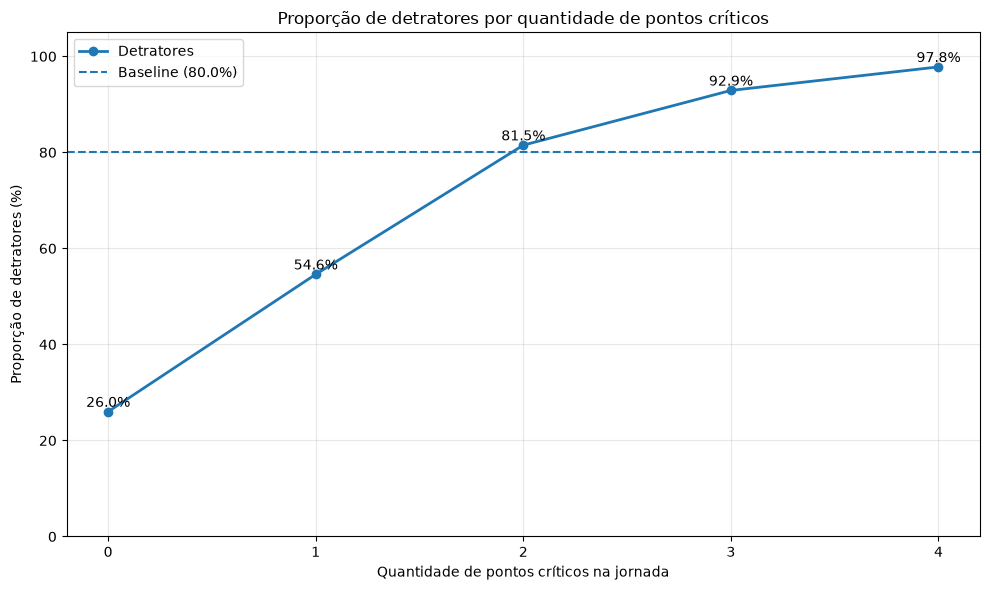

In [57]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    acumulo_atritos.index,
    acumulo_atritos['Detrator'],
    marker='o',
    linewidth=2,
    label='Detratores'
)

# Linha do baseline
ax.axhline(
    y=baseline_detratores,
    linestyle='--',
    label=f'Baseline ({baseline_detratores:.1f}%)'
)

# Rótulos dos pontos
for x, y in zip(
    acumulo_atritos.index,
    acumulo_atritos['Detrator']
):
    ax.text(
        x,
        y + 1,
        f'{y:.1f}%',
        ha='center'
    )

ax.set_title(
    'Proporção de detratores por quantidade de pontos críticos'
)

ax.set_xlabel(
    'Quantidade de pontos críticos na jornada'
)

ax.set_ylabel(
    'Proporção de detratores (%)'
)

ax.set_xticks(acumulo_atritos.index)

ax.set_ylim(0, 105)

ax.legend()

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Análise**

Com os limites utilizados, a proporção de detratores aumenta de 25,98% sem condições de atrito para 54,60% com uma, 81,47% com duas, 92,92% com três e 97,85% com quatro.

Os grupos com três ou quatro condições se diferenciam mais do percentual geral da base. Com duas, o resultado ainda está próximo dos 80,04% gerais.

Foram mantidos os limites de dois dias de atraso, dois contatos, quatro reclamações e quatro dias de resolução como critérios exploratórios. O limite de resolução não representa uma ruptura comprovada. Além disso, contatos e reclamações estão relacionados e podem contar partes do mesmo problema.

# 4. Investigação de possíveis fatores associados ao atraso

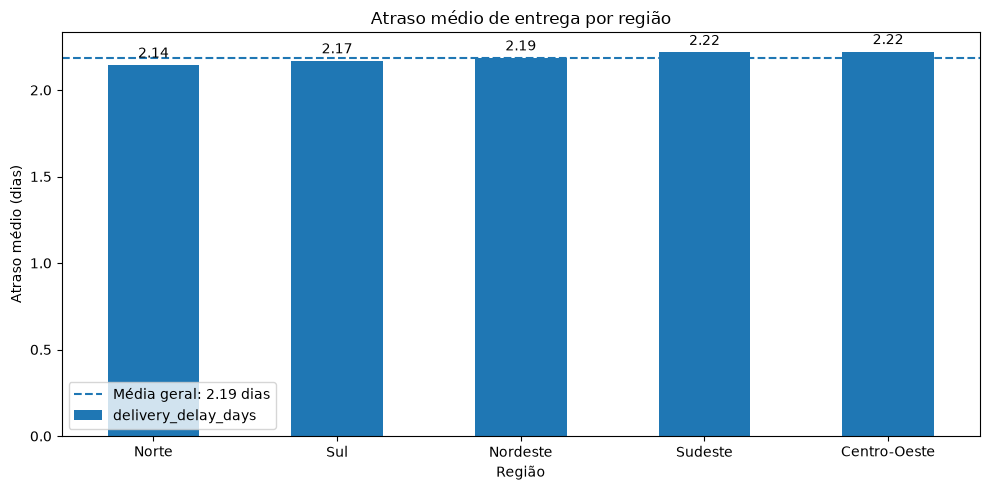

In [58]:
# Calculando o atraso médio por região
atraso_regiao = (
    df.groupby('customer_region')['delivery_delay_days']
      .mean()
      .sort_values()
)

# Média geral
media_geral = df['delivery_delay_days'].mean()

# Criando o gráfico
fig, ax = plt.subplots(figsize=(10, 5))

atraso_regiao.plot(
    kind='bar',
    ax=ax
)

# Linha da média geral
ax.axhline(
    y=media_geral,
    linestyle='--',
    label=f'Média geral: {media_geral:.2f} dias'
)

ax.set_title('Atraso médio de entrega por região')
ax.set_xlabel('Região')
ax.set_ylabel('Atraso médio (dias)')

ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )

ax.legend()

plt.tight_layout()
plt.show()

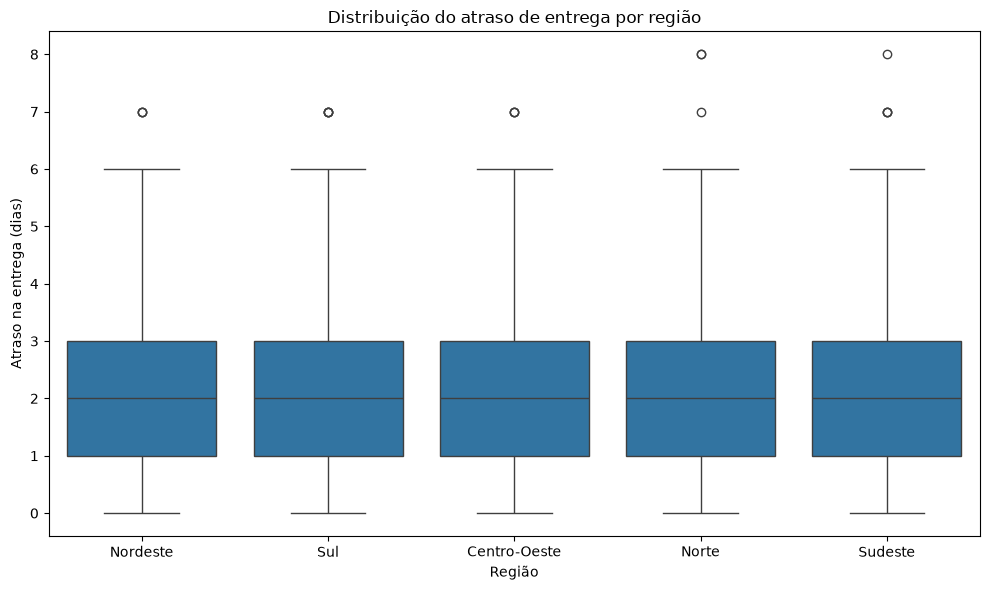

In [59]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='customer_region',
    y='delivery_delay_days',
    ax=ax
)

ax.set_title('Distribuição do atraso de entrega por região')
ax.set_xlabel('Região')
ax.set_ylabel('Atraso na entrega (dias)')

ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**Análise regional**

Os atrasos médios são de 2,22 dias no Centro-Oeste, 2,19 no Nordeste, 2,14 no Norte, 2,22 no Sudeste e 2,17 no Sul. A diferença entre a maior e a menor média é inferior a 0,08 dia. Os grupos também têm tamanhos próximos, entre 468 e 521 registros.

As distribuições e as médias não destacam uma região como prioridade evidente para explicar o atraso geral. Isso sugere investigar processos e condições de entrega em um nível mais detalhado antes de concentrar uma intervenção em uma região inteira.

Essa semelhança não prova que todas as rotas ou transportadoras tenham o mesmo desempenho. Diferenças locais podem ficar escondidas na média regional. Também não permite concluir que exista uma causa estrutural comum: faltam dados das etapas da operação.

## 4.2 Tentativas de entrega e atraso

In [60]:
# Atraso médio por número de tentativas de entrega
atraso_tentativas = (
    df.groupby('delivery_attempts')['delivery_delay_days']
      .mean()
      .round(2)
)

atraso_tentativas

delivery_attempts
1    2.15
2    2.25
3    2.16
Name: delivery_delay_days, dtype: float64

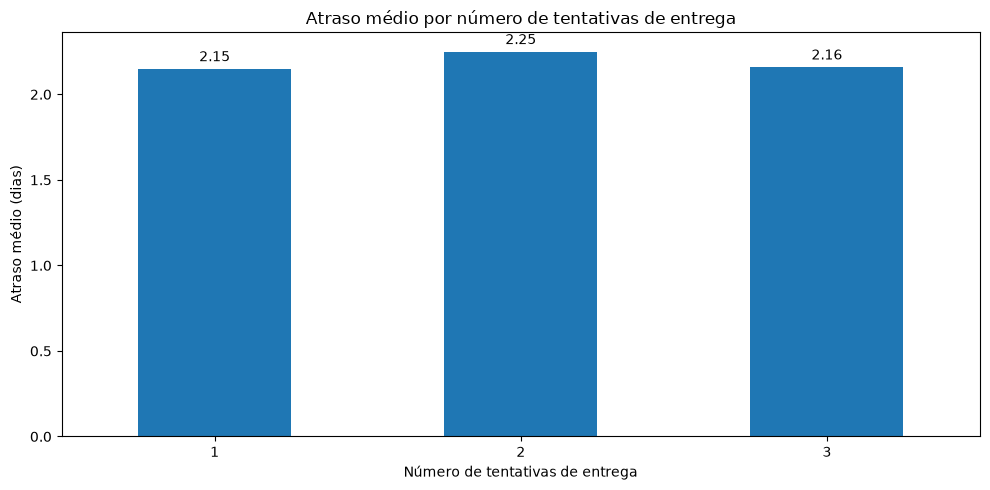

In [61]:
fig, ax = plt.subplots(figsize=(10, 5))

atraso_tentativas.plot(
    kind='bar',
    ax=ax
)

ax.set_title('Atraso médio por número de tentativas de entrega')
ax.set_xlabel('Número de tentativas de entrega')
ax.set_ylabel('Atraso médio (dias)')

ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )

plt.tight_layout()
plt.show()

## 4.3 Tentativas de entrega e classificação NPS

In [62]:
tentativas_nps = (
    df.groupby('clas_cliente')['delivery_attempts']
      .mean()
      .round(2)
)

tentativas_nps

clas_cliente
Detrator      2.00
Neutro        2.03
Promotores    2.09
Name: delivery_attempts, dtype: float64

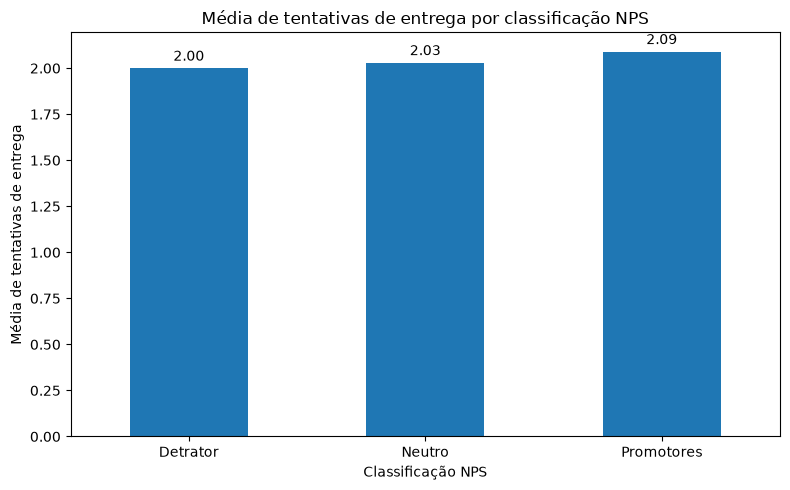

In [63]:
fig, ax = plt.subplots(figsize=(8, 5))

tentativas_nps.plot(
    kind='bar',
    ax=ax
)

ax.set_title('Média de tentativas de entrega por classificação NPS')
ax.set_xlabel('Classificação NPS')
ax.set_ylabel('Média de tentativas de entrega')

ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )

plt.tight_layout()
plt.show()

## 4.4 Frete e atraso

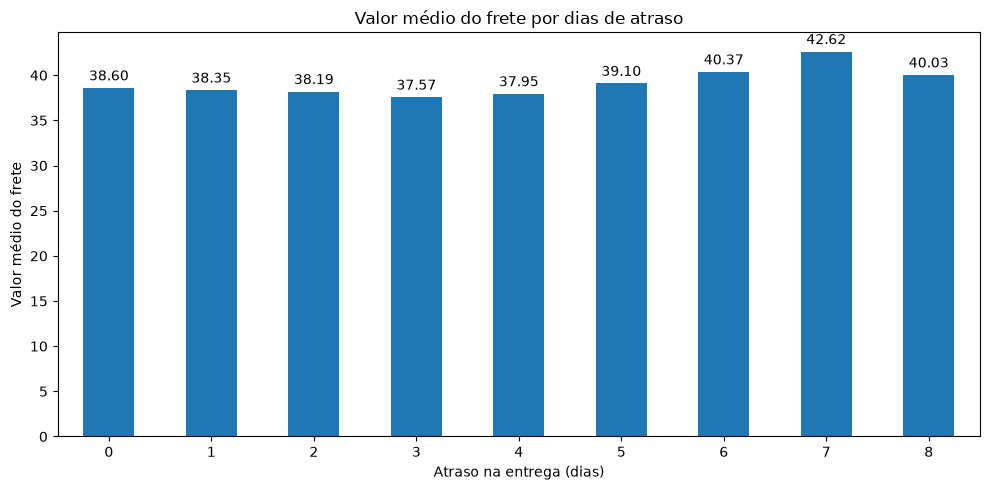

In [64]:
frete_atraso = (
    df.groupby('delivery_delay_days')['freight_value']
      .mean()
      .round(2)
)

fig, ax = plt.subplots(figsize=(10, 5))

frete_atraso.plot(
    kind='bar',
    ax=ax
)

ax.set_title('Valor médio do frete por dias de atraso')
ax.set_xlabel('Atraso na entrega (dias)')
ax.set_ylabel('Valor médio do frete')

ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )

plt.tight_layout()
plt.show()

**Análise**

Com uma tentativa de entrega, o atraso médio é de 2,15 dias; com duas, de 2,25; e com três, de 2,17. Os grupos têm tamanhos semelhantes, entre 824 e 838 registros. Não há crescimento progressivo do atraso conforme aumentam as tentativas. Portanto, essa variável não oferece, isoladamente, uma explicação clara para os atrasos da amostra.

A quantidade média de tentativas também é próxima entre as classificações: 2,00 entre detratores, 2,03 entre neutros e 2,09 entre promotores. Isso contrasta com as diferenças maiores observadas em atraso e atendimento. A contagem de tentativas, sozinha, parece menos útil para diferenciar a satisfação.

O frete médio permanece entre aproximadamente 37,57 e 39,10 nas faixas de zero a cinco dias de atraso. Nos atrasos de seis a oito dias, as médias são maiores, mas baseadas em apenas 34, 14 e 3 registros. Não é adequado concluir que um frete maior esteja associado a pior entrega com base nessa cauda pequena.

A análise não localiza a origem do atraso. O próximo aprofundamento operacional exigiria prazo prometido, tempo de expedição, transportadora e rota, em vez de assumir uma causa a partir dessas médias.

# 4.5 Satisfação e recompra

In [65]:
numero_detratores_recompra = pd.crosstab(
    df['clas_cliente'],
    df['repeat_purchase_30d']
)

In [66]:
numero_detratores_recompra 

repeat_purchase_30d,0,1
clas_cliente,,
Detrator,2001,0
Neutro,281,70
Promotores,0,148


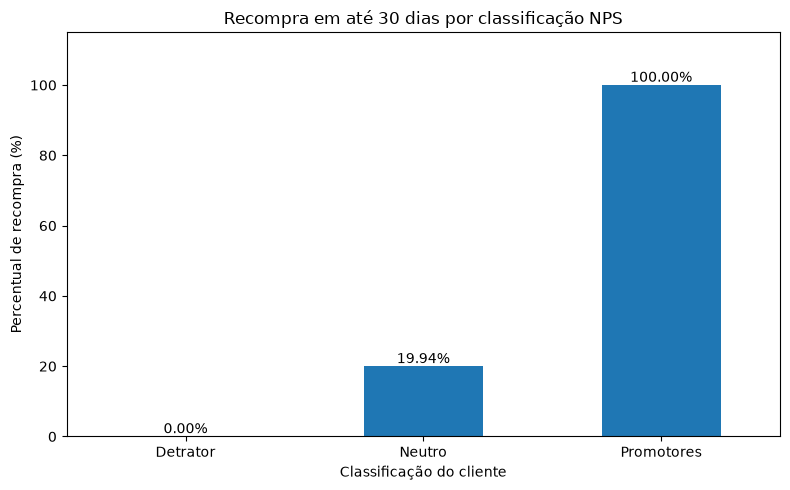

In [67]:
percentual_recompra_classe = (
    df.groupby('clas_cliente')['repeat_purchase_30d']
    .mean()
    .mul(100)
    .reindex(['Detrator', 'Neutro', 'Promotores'])
)

fig, ax = plt.subplots(figsize=(8, 5))
percentual_recompra_classe.plot(kind='bar', ax=ax)
ax.set_title('Recompra em até 30 dias por classificação NPS')
ax.set_xlabel('Classificação do cliente')
ax.set_ylabel('Percentual de recompra (%)')
ax.set_ylim(0, 115)
ax.tick_params(axis='x', rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')
plt.tight_layout()
plt.show()

A recompra ocorre em 0% dos detratores, 19,94% dos neutros e 100% dos promotores. São, respectivamente, 0 de 2.001, 70 de 351 e 148 de 148 clientes.

A separação exata dos grupos extremos merece confirmação na documentação da base. Sem datas e informações sobre a coleta, não é possível determinar a ordem entre avaliação e recompra.

# 5. Conclusão

A base apresenta 80,04% de detratores e NPS de −74,12 após o arredondamento das notas. Atraso, reclamações e contatos com atendimento são os principais indicadores operacionais a aprofundar.

As diferenças entre as classificações aparecem nos valores típicos e nos casos extremos. Os registros com atrasos elevados, muitos contatos ou muitas reclamações apresentam notas médias menores. O tempo de resolução também se relaciona ao NPS, mas apresenta um comportamento menos definido.

A proporção de detratores aumenta com o acúmulo das condições analisadas, chegando a 92,92% com três e 97,85% com quatro. Isso reforça a importância de acompanhar a experiência como um todo.

**Recomendações**

- Acompanhar atrasos, contatos recorrentes e reclamações.
- Investigar os motivos dos contatos e sua relação com entrega e resolução.
- Avaliar os casos extremos sem removê-los automaticamente.
- Incluir dados de transportadora, expedição e prazo prometido para investigar os atrasos.

**Limitações**

O arredondamento modifica classificações e precisa ser confirmado com a origem dos dados. Não há informação suficiente sobre o período, a seleção da amostra ou a sequência dos eventos. As relações são descritivas e não demonstram causalidade.

Os limites usados no acúmulo de atritos são exploratórios. Não foram realizados testes para demonstrar significância estatística ou confirmar pontos de ruptura. A separação entre recompra de detratores e promotores também precisa ser conferida na documentação da base.